# Assignment 1: Behavioral Analysis of Memory Search

In this assignment, we use the BIDS-formatted PEERS data (ltpFR, ltpFR2, FR1, VFFR).
Reusable behavioral helpers (serial position, recalled, intrusion, rectime, ...)
live in `BehavioralHelpers.py` so the notebook stays focused on the analyses.


In [1]:
# grader setup — enables saving the figures you plot (run once, early)
try:
    from grader.answer_io import enable_figure_capture
    enable_figure_capture()
except Exception as _e:
    print("grader: figure capture not enabled:", _e)


In [2]:
import pandas as pd; pd.set_option('display.max_columns', None)
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import sys, os
sys.path.insert(0, ".")
sys.path.insert(0, "dependencies/bidsreader")
from cml_data import dataset_root, get_bids_root, session_dataframe
from bidsreader import CMLBIDSReader as BIDSReader

import BehavioralHelpers as bh

# Per-task BIDS roots. Each task is its own OpenNeuro dataset; dataset_root()
# returns the cluster copy if present, else the local ./bids_data cache.
LTPFR2_ROOT = str(dataset_root("ltpFR2"))
LTPFR_ROOT  = str(dataset_root("ltpFR"))
FR1_ROOT    = str(dataset_root("FR1"))
VFFR_ROOT   = str(dataset_root("VFFR"))


## Question 1: Navigating the database

1) How many sessions of `vffr` were run? How many subjects did at least 1 session of `vffr`?
2) What is the max number of sessions a single subject ran for `vffr`, and which subjects ran that many?


In [3]:
# Question 1.1
df_vffr = session_dataframe("VFFR")
sess_cnt = len(df_vffr)
sub_cnt  = df_vffr["subject"].nunique()
print(f"{sess_cnt} sessions across {sub_cnt} subjects")


462 sessions across 57 subjects


In [4]:
# ── grader cell (Question 1.1) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q1.1_n_sessions_vffr", sess_cnt, module=3, question="1.1")
save_answer("Q1.1_n_subjects_vffr", sub_cnt, module=3, question="1.1")

{'key': 'Q1.1_n_subjects_vffr',
 'question': '1.1',
 'role': 'plot',
 'desc': None,
 'type': 'scalar',
 'file': None,
 'value': 57,
 'shape': None,
 'dtype': None,
 'columns': None,
 'fig': None}

In [5]:
# Question 1.2
sess_per_sub = df_vffr.groupby("subject").size()
max_sess = sess_per_sub.max()
max_subs = sess_per_sub[sess_per_sub == max_sess].index.tolist()
print(f"{max_sess} is the max number of sessions run by a single subject")
print(f"Subjects with {max_sess} sessions: {max_subs}")


10 is the max number of sessions run by a single subject
Subjects with 10 sessions: ['LTP229', 'LTP246', 'LTP339', 'LTP347', 'LTP355', 'LTP356', 'LTP365', 'LTP372', 'LTP400', 'LTP401', 'LTP402', 'LTP404', 'LTP405', 'LTP406', 'LTP407', 'LTP408', 'LTP411', 'LTP412', 'LTP413', 'LTP415', 'LTP416', 'LTP417', 'LTP418', 'LTP419', 'LTP421', 'LTP423', 'LTP424', 'LTP425', 'LTP429', 'LTP430']


In [6]:
# ── grader cell (Question 1.2) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q1.2_max_sessions_vffr", max_sess, module=3, question="1.2")
save_answer("Q1.2_max_session_subjects", max_subs, module=3, question="1.2")

{'key': 'Q1.2_max_session_subjects',
 'question': '1.2',
 'role': 'plot',
 'desc': None,
 'type': 'json',
 'file': None,
 'value': ['LTP229',
  'LTP246',
  'LTP339',
  'LTP347',
  'LTP355',
  'LTP356',
  'LTP365',
  'LTP372',
  'LTP400',
  'LTP401',
  'LTP402',
  'LTP404',
  'LTP405',
  'LTP406',
  'LTP407',
  'LTP408',
  'LTP411',
  'LTP412',
  'LTP413',
  'LTP415',
  'LTP416',
  'LTP417',
  'LTP418',
  'LTP419',
  'LTP421',
  'LTP423',
  'LTP424',
  'LTP425',
  'LTP429',
  'LTP430'],
 'shape': None,
 'dtype': None,
 'columns': None,
 'fig': None}

## Question 2: Simple Behavioral Analyses

1) What is R1111M's overal recall percentage?  (In other words what percent of the words did R1111M successfully recall?)
2) Calculate R1111M’s recall percentage for each list within each session. Then, average these values across sessions to obtain a mean recall percentage for each list. Plot the results in a bar graph.

In [7]:
# Question 2.1
sub, task = "R1111M", "FR1"
df_fr1 = session_dataframe(task)
df_sub = df_fr1[df_fr1["subject"] == sub]
print(f"{sub} sessions: {df_sub['session'].tolist()}")

recalled, total = 0, 0
for _, row in df_sub.iterrows():
    try:
        word_evs, _ = bh.load_and_prepare(FR1_ROOT, sub, task, row["session"])
    except Exception as e:
        print(f"  skipping ses-{row['session']}: {e}")
        continue
    recalled += int(word_evs["recalled"].sum())
    total    += len(word_evs)

recall_pct = 100 * recalled / total   # bound for the grader (Q2.1)
print(f"{recall_pct:.2f}% correct ({recalled}/{total})")

R1111M sessions: ['0', '1', '2', '3']
53.92% correct (550/1020)


In [8]:
# ── grader cell (Question 2.1) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q2.1_recall_pct", recall_pct, module=3, question="2.1")

{'key': 'Q2.1_recall_pct',
 'question': '2.1',
 'role': 'plot',
 'desc': None,
 'type': 'scalar',
 'file': None,
 'value': 53.92156862745098,
 'shape': None,
 'dtype': None,
 'columns': None,
 'fig': None}

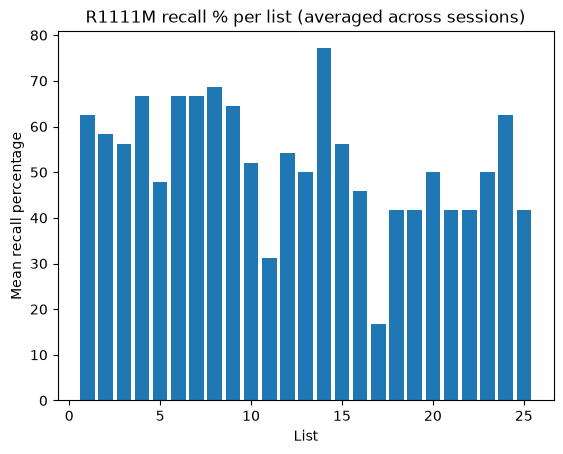

In [9]:
# Question 2.2  -- recall percentage per list, averaged across sessions (bar graph)
# reuse sub / task / df_sub (R1111M's FR1 sessions) from Question 2.1
per_session = []          # one Series per session: list number -> recall % (0-100)
for _, row in df_sub.iterrows():
    try:
        word_evs, _ = bh.load_and_prepare(FR1_ROOT, sub, task, row["session"])
    except Exception as e:
        print(f"  skipping ses-{row['session']}: {e}")
        continue
    # list number lives in 'list' (fall back to 'trial')
    list_col = "list" if "list" in word_evs.columns and word_evs["list"].notna().any() else "trial"
    per_session.append(100 * word_evs.groupby(list_col)["recalled"].mean())

# average each list's recall percentage across sessions
mean_by_list = pd.concat(per_session, axis=1).mean(axis=1).sort_index()
recall_pct_per_list = mean_by_list.to_numpy()   # the bar-graph heights (Q2.2 answer)

plt.bar(mean_by_list.index.to_numpy(), recall_pct_per_list)
plt.xlabel("List")
plt.ylabel("Mean recall percentage")
plt.title(f"{sub} recall % per list (averaged across sessions)")
plt.show()

In [10]:
# ── grader cell (Question 2.2) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q2.2_recall_pct_per_list", recall_pct_per_list, module=3, question="2.2", fig="last")

{'key': 'Q2.2_recall_pct_per_list',
 'question': '2.2',
 'role': 'plot',
 'desc': None,
 'type': 'array',
 'file': 'Q2.2_recall_pct_per_list.npy',
 'value': None,
 'shape': [25],
 'dtype': 'float64',
 'columns': None,
 'fig': 'Q2.2_recall_pct_per_list.png'}

## Question 3: Serial Position Curve
A serial position curve (SPC) plots the recall probability (vertical axis) as a function of serial position (horizontal axis), as shown in figure 6.1 of FHM.  We define recall probability as the fraction of words successfully recalled.  As with any analyses, there are numerous ways to calculate the SPC, but a good hint is to look at the "recalled" status of each presented word.

1) Write a function to calculate the recall probabilities at each serial position for 1 session.  Then calculate the SPC for subject LTP093, session 0 of ltpFR2, and plot the results.
2) Write a function to calculate the SPC for all sessions for 1 subject.  Then plot the SPC averaged over all of LTP093's ltpFR2 sessions.
3) Write a function that loops over selected subjects from ltpFR2 and computes a between-subject averaged serial position curve.  This is done by averaging the subject-level SPCs across all subjects.  Comment on the final SPC, what effects does it show?

If you are smart about it, you should be able to use code from earlier parts of the problem to make later parts much easier!

A few notes:
* Generally, each experimental subject will have different characteristics. A subject-level average provides an estimate of the population mean, i.e. the mean of the population from which these subjects were sampled from (which in the case of LTPFR2, was primarily Penn undergraduates).
* Loading these data may take a substantial amount of time. You may want to write your code and then test it over a smaller number of subjects (e.g., 2 subjects). You may also want to load all the data once and then save it out locally as a .csv file (see the pandas.DataFrame.to_csv() function in the pandas documentation). You will then be able to load all of these events from this .csv file much more quickly (see the pandas.read_csv() function).
    * Again, some subjects did not complete all sessions. To reduce the variability in your estimates, include only the subjects that completed all 24 sessions. Additionally, drop the 24th session (which has session number 23 since the sessions are zero-indexed) which used a different variant of the experiment.
    
* Be sure that your code is robust to exceptions that can be thrown by e.g. unavailable data, and if you have an exception in a particular session due to a problem with the data in that session, print or log the event so you can report it, and discard that session from the analysis (you can use Python try-except blocks to catch and handle exceptions). This data was all acquired with human participants across long stretches of time, and small things can go wrong.

In [11]:
# Selected ltpFR2 cohort (subjects who completed all 24 sessions)
ltpFR2_subs = ['LTP093', 'LTP106', 'LTP115', 'LTP117', 'LTP122', 'LTP123', 'LTP133', 'LTP138', 'LTP187', 'LTP207',
               'LTP210', 'LTP228', 'LTP229', 'LTP236', 'LTP242', 'LTP246', 'LTP249', 'LTP250', 'LTP251', 'LTP258',
               'LTP259', 'LTP260', 'LTP265', 'LTP269', 'LTP273', 'LTP274', 'LTP278', 'LTP279', 'LTP280', 'LTP281']

df_ltpfr2 = session_dataframe("ltpFR2")
cnt_good = sum(
    df_ltpfr2[df_ltpfr2['subject'] == s]['session'].nunique() == 24
    for s in ltpFR2_subs
)
print(f"{cnt_good}/{len(ltpFR2_subs)} cohort subjects have 24 sessions")


25/30 cohort subjects have 24 sessions


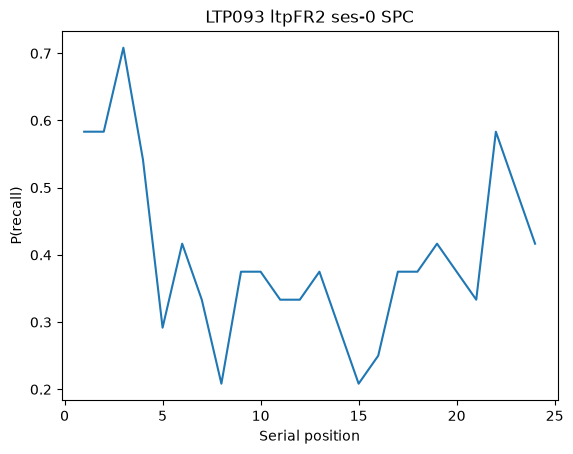

In [12]:
# Question 3.1 -- single session SPC
word_evs, _ = bh.load_and_prepare(LTPFR2_ROOT, "LTP093", "ltpFR2", 0)
spc = bh.compute_spc(word_evs)
plt.plot(spc["serialpos"], spc["recalled"])
plt.title("LTP093 ltpFR2 ses-0 SPC")
plt.xlabel("Serial position")
plt.ylabel("P(recall)")
plt.show()


In [13]:
# ── grader cell (Question 3.1) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q3.1_spc_ltp093_ses0", spc, module=3, question="3.1", fig="last")

{'key': 'Q3.1_spc_ltp093_ses0',
 'question': '3.1',
 'role': 'plot',
 'desc': None,
 'type': 'dataframe',
 'file': 'Q3.1_spc_ltp093_ses0.pkl',
 'value': None,
 'shape': [24, 2],
 'dtype': None,
 'columns': ['serialpos', 'recalled'],
 'fig': 'Q3.1_spc_ltp093_ses0.png'}

  (prefetch skipped: <urlopen error [Errno 8] nodename nor servname provided, or not known>)


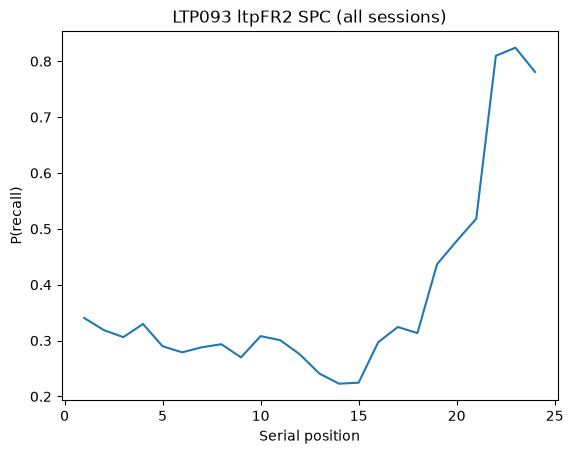

In [14]:
# Question 3.2 -- single subject, all sessions
all_word_ltpfr2, all_rec_ltpfr2 = bh.collect_events(
    LTPFR2_ROOT, "ltpFR2", subjects=ltpFR2_subs
)

# cache so we don't reload
import os
os.makedirs("data", exist_ok=True)
all_word_ltpfr2.to_csv("data/LTPFR2_word_evs.csv", index=False)
all_rec_ltpfr2.to_csv("data/LTPFR2_rec_evs.csv", index=False)

sub = "LTP093"
sub_words = all_word_ltpfr2[
    (all_word_ltpfr2["subject"] == sub) & (all_word_ltpfr2["session"] != 23)
]
spc = bh.compute_spc(sub_words)
plt.plot(spc["serialpos"], spc["recalled"])
plt.title(f"{sub} ltpFR2 SPC (all sessions)")
plt.xlabel("Serial position")
plt.ylabel("P(recall)")
plt.show()


In [15]:
# ── grader cell (Question 3.2) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q3.2_spc_ltp093_all", spc, module=3, question="3.2", fig="last")

{'key': 'Q3.2_spc_ltp093_all',
 'question': '3.2',
 'role': 'plot',
 'desc': None,
 'type': 'dataframe',
 'file': 'Q3.2_spc_ltp093_all.pkl',
 'value': None,
 'shape': [24, 2],
 'dtype': None,
 'columns': ['serialpos', 'recalled'],
 'fig': 'Q3.2_spc_ltp093_all.png'}

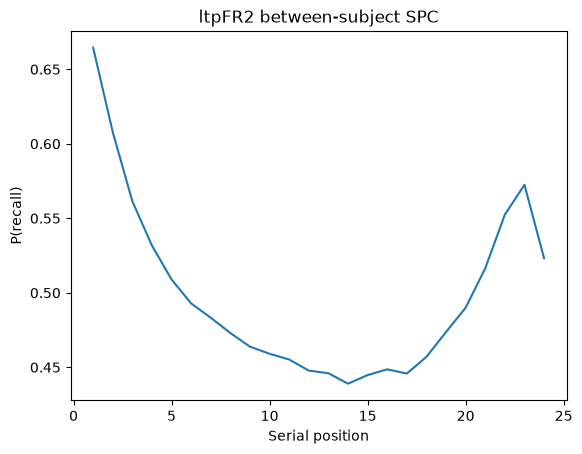

In [16]:
# Question 3.3 -- between-subject averaged SPC
sub_spcs = []
for sub, evs in all_word_ltpfr2.groupby("subject"):
    if evs["session"].nunique() != 24:
        continue
    evs = evs[evs["session"] != 23]
    spc = bh.compute_spc(evs)
    spc["subject"] = sub
    sub_spcs.append(spc)

ave_spc = (
    pd.concat(sub_spcs, ignore_index=True)
    .groupby("serialpos", as_index=False)["recalled"]
    .mean()
)
plt.plot(ave_spc["serialpos"], ave_spc["recalled"])
plt.title("ltpFR2 between-subject SPC")
plt.xlabel("Serial position")
plt.ylabel("P(recall)")
plt.show()


In [17]:
# ── grader cell (Question 3.3) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q3.3_ave_spc", ave_spc, module=3, question="3.3", fig="last")

{'key': 'Q3.3_ave_spc',
 'question': '3.3',
 'role': 'plot',
 'desc': None,
 'type': 'dataframe',
 'file': 'Q3.3_ave_spc.pkl',
 'value': None,
 'shape': [24, 2],
 'dtype': None,
 'columns': ['serialpos', 'recalled'],
 'fig': 'Q3.3_ave_spc.png'}

**Comment:** the SPC shows the classic primacy (elevated recall for the
first few items) and recency (elevated recall for the last few items) effects,
with the lowest recall in the middle of the list.


## Question 4: Immediate Free Recall v. Delayed Free Recall

In this question, we will use the ltpFR experiment to compare the SPCs for immediate free recall and delayed free recall. For each subject, use sessions 7-13 and compare lists with between-words 'distractor' = 0 and end-of-list 'final_distractor' = 0, and 16000 (ms).

1) Calculate between-subject averaged serial position curves for each of the 2 distractor conditions.  Plot the 2 SPCs on the same graph and label each curve in a legend.
2) Comment on the differences in the SPCs that result from the manipulation of the distractor.  What changes between immediate free recall and delayed free recall?

In [18]:
# Load every ltpFR session 7-13, recovering BOTH distractor fields per list.
df_ltpfr = session_dataframe("ltpFR")
df_ltpfr["session_int"] = df_ltpfr["session"].astype(int)
df_sub = df_ltpfr[(df_ltpfr["session_int"] >= 7) & (df_ltpfr["session_int"] <= 13)]

word_frames = []
for row in df_sub.itertuples():
    try:
        events = bh.load_session_events(LTPFR_ROOT, row.subject, "ltpFR", row.session)
        events = bh.add_final_distractor_from_gap(events)        # end-of-list distractor
        events = bh.add_between_word_distractor_from_isi(events) # between-words distractor
        word_evs = bh.get_word_events(events)
        rec_evs  = bh.get_rec_events(events)
        word_evs = bh.add_serialpos(word_evs)
        word_evs = bh.add_recalled(word_evs, rec_evs)
        word_frames.append(word_evs)
    except Exception as e:
        print(f"  skipping {row.subject} ses-{row.session}: {e}")

all_word_ltpfr = pd.concat(word_frames, ignore_index=True)
print("loaded", len(all_word_ltpfr), "WORD rows")
print("distractor x final_distractor counts:")
print(all_word_ltpfr.groupby(["distractor", "final_distractor"]).size())


  skipping LTP093 ses-10: load_events: no file matched for bids_data/ds004395/sub-LTP093/ses-10/beh/sub-LTP093_ses-10_task-ltpFR_beh.tsv
  skipping LTP093 ses-11: load_events: no file matched for bids_data/ds004395/sub-LTP093/ses-11/beh/sub-LTP093_ses-11_task-ltpFR_beh.tsv
  skipping LTP093 ses-12: load_events: no file matched for bids_data/ds004395/sub-LTP093/ses-12/beh/sub-LTP093_ses-12_task-ltpFR_beh.tsv
  skipping LTP093 ses-13: load_events: no file matched for bids_data/ds004395/sub-LTP093/ses-13/beh/sub-LTP093_ses-13_task-ltpFR_beh.tsv
  skipping LTP093 ses-7: load_events: no file matched for bids_data/ds004395/sub-LTP093/ses-7/beh/sub-LTP093_ses-7_task-ltpFR_beh.tsv
  skipping LTP093 ses-8: load_events: no file matched for bids_data/ds004395/sub-LTP093/ses-8/beh/sub-LTP093_ses-8_task-ltpFR_beh.tsv
  skipping LTP093 ses-9: load_events: no file matched for bids_data/ds004395/sub-LTP093/ses-9/beh/sub-LTP093_ses-9_task-ltpFR_beh.tsv


  skipping LTP106 ses-10: load_events: no file matched for bids_data/ds004395/sub-LTP106/ses-10/beh/sub-LTP106_ses-10_task-ltpFR_beh.tsv
  skipping LTP106 ses-11: load_events: no file matched for bids_data/ds004395/sub-LTP106/ses-11/beh/sub-LTP106_ses-11_task-ltpFR_beh.tsv
  skipping LTP106 ses-12: load_events: no file matched for bids_data/ds004395/sub-LTP106/ses-12/beh/sub-LTP106_ses-12_task-ltpFR_beh.tsv
  skipping LTP106 ses-13: load_events: no file matched for bids_data/ds004395/sub-LTP106/ses-13/beh/sub-LTP106_ses-13_task-ltpFR_beh.tsv
  skipping LTP106 ses-7: load_events: no file matched for bids_data/ds004395/sub-LTP106/ses-7/beh/sub-LTP106_ses-7_task-ltpFR_beh.tsv
  skipping LTP106 ses-8: load_events: no file matched for bids_data/ds004395/sub-LTP106/ses-8/beh/sub-LTP106_ses-8_task-ltpFR_beh.tsv
  skipping LTP106 ses-9: load_events: no file matched for bids_data/ds004395/sub-LTP106/ses-9/beh/sub-LTP106_ses-9_task-ltpFR_beh.tsv


  skipping LTP115 ses-10: load_events: no file matched for bids_data/ds004395/sub-LTP115/ses-10/beh/sub-LTP115_ses-10_task-ltpFR_beh.tsv
  skipping LTP115 ses-11: load_events: no file matched for bids_data/ds004395/sub-LTP115/ses-11/beh/sub-LTP115_ses-11_task-ltpFR_beh.tsv
  skipping LTP115 ses-12: load_events: no file matched for bids_data/ds004395/sub-LTP115/ses-12/beh/sub-LTP115_ses-12_task-ltpFR_beh.tsv
  skipping LTP115 ses-13: load_events: no file matched for bids_data/ds004395/sub-LTP115/ses-13/beh/sub-LTP115_ses-13_task-ltpFR_beh.tsv
  skipping LTP115 ses-7: load_events: no file matched for bids_data/ds004395/sub-LTP115/ses-7/beh/sub-LTP115_ses-7_task-ltpFR_beh.tsv
  skipping LTP115 ses-8: load_events: no file matched for bids_data/ds004395/sub-LTP115/ses-8/beh/sub-LTP115_ses-8_task-ltpFR_beh.tsv
  skipping LTP115 ses-9: load_events: no file matched for bids_data/ds004395/sub-LTP115/ses-9/beh/sub-LTP115_ses-9_task-ltpFR_beh.tsv
  skipping LTP117 ses-10: load_events: no file mat

  skipping LTP122 ses-10: load_events: no file matched for bids_data/ds004395/sub-LTP122/ses-10/beh/sub-LTP122_ses-10_task-ltpFR_beh.tsv
  skipping LTP122 ses-11: load_events: no file matched for bids_data/ds004395/sub-LTP122/ses-11/beh/sub-LTP122_ses-11_task-ltpFR_beh.tsv
  skipping LTP122 ses-12: load_events: no file matched for bids_data/ds004395/sub-LTP122/ses-12/beh/sub-LTP122_ses-12_task-ltpFR_beh.tsv
  skipping LTP122 ses-13: load_events: no file matched for bids_data/ds004395/sub-LTP122/ses-13/beh/sub-LTP122_ses-13_task-ltpFR_beh.tsv
  skipping LTP122 ses-7: load_events: no file matched for bids_data/ds004395/sub-LTP122/ses-7/beh/sub-LTP122_ses-7_task-ltpFR_beh.tsv
  skipping LTP122 ses-8: load_events: no file matched for bids_data/ds004395/sub-LTP122/ses-8/beh/sub-LTP122_ses-8_task-ltpFR_beh.tsv
  skipping LTP122 ses-9: load_events: no file matched for bids_data/ds004395/sub-LTP122/ses-9/beh/sub-LTP122_ses-9_task-ltpFR_beh.tsv
  skipping LTP123 ses-10: load_events: no file mat

  skipping LTP133 ses-10: load_events: no file matched for bids_data/ds004395/sub-LTP133/ses-10/beh/sub-LTP133_ses-10_task-ltpFR_beh.tsv
  skipping LTP133 ses-11: load_events: no file matched for bids_data/ds004395/sub-LTP133/ses-11/beh/sub-LTP133_ses-11_task-ltpFR_beh.tsv
  skipping LTP133 ses-12: load_events: no file matched for bids_data/ds004395/sub-LTP133/ses-12/beh/sub-LTP133_ses-12_task-ltpFR_beh.tsv
  skipping LTP133 ses-13: load_events: no file matched for bids_data/ds004395/sub-LTP133/ses-13/beh/sub-LTP133_ses-13_task-ltpFR_beh.tsv
  skipping LTP133 ses-7: load_events: no file matched for bids_data/ds004395/sub-LTP133/ses-7/beh/sub-LTP133_ses-7_task-ltpFR_beh.tsv
  skipping LTP133 ses-8: load_events: no file matched for bids_data/ds004395/sub-LTP133/ses-8/beh/sub-LTP133_ses-8_task-ltpFR_beh.tsv
  skipping LTP133 ses-9: load_events: no file matched for bids_data/ds004395/sub-LTP133/ses-9/beh/sub-LTP133_ses-9_task-ltpFR_beh.tsv


...

  skipping LTP391 ses-12: load_events: no file matched for bids_data/ds004395/sub-LTP391/ses-12/beh/sub-LTP391_ses-12_task-ltpFR_beh.tsv


  skipping LTP391 ses-13: load_events: no file matched for bids_data/ds004395/sub-LTP391/ses-13/beh/sub-LTP391_ses-13_task-ltpFR_beh.tsv


  skipping LTP391 ses-7: load_events: no file matched for bids_data/ds004395/sub-LTP391/ses-7/beh/sub-LTP391_ses-7_task-ltpFR_beh.tsv


  skipping LTP391 ses-8: load_events: no file matched for bids_data/ds004395/sub-LTP391/ses-8/beh/sub-LTP391_ses-8_task-ltpFR_beh.tsv


  skipping LTP391 ses-9: load_events: no file matched for bids_data/ds004395/sub-LTP391/ses-9/beh/sub-LTP391_ses-9_task-ltpFR_beh.tsv
  skipping LTP393 ses-10: load_events: no file matched for bids_data/ds004395/sub-LTP393/ses-10/beh/sub-LTP393_ses-10_task-ltpFR_beh.tsv
  skipping LTP393 ses-11: load_events: no file matched for bids_data/ds004395/sub-LTP393/ses-11/beh/sub-LTP393_ses-11_task-ltpFR_beh.tsv
  skipping LTP393 ses-12: load_events: no file matched for bids_data/ds004395/sub-LTP393/ses-12/beh/sub-LTP393_ses-12_task-ltpFR_beh.tsv
  skipping LTP393 ses-13: load_events: no file matched for bids_data/ds004395/sub-LTP393/ses-13/beh/sub-LTP393_ses-13_task-ltpFR_beh.tsv
  skipping LTP393 ses-7: load_events: no file matched for bids_data/ds004395/sub-LTP393/ses-7/beh/sub-LTP393_ses-7_task-ltpFR_beh.tsv
  skipping LTP393 ses-8: load_events: no file matched for bids_data/ds004395/sub-LTP393/ses-8/beh/sub-LTP393_ses-8_task-ltpFR_beh.tsv
  skipping LTP393 ses-9: load_events: no file matc

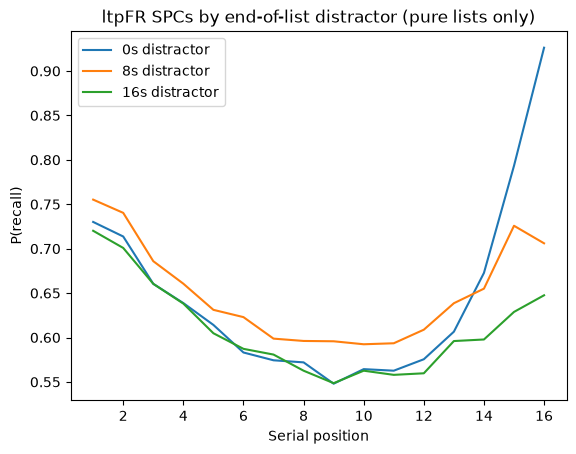

In [19]:
spcs_by_cond = {}
for cond in [0, 8000, 16000]:
    evs_cond = all_word_ltpfr[
        (all_word_ltpfr["distractor"] == 0)
        & (all_word_ltpfr["final_distractor"] == cond)
    ]
    evs_cond = evs_cond.query('session >= 7 and session <= 13')

    sub_spcs = []
    for sub, evs in evs_cond.groupby("subject"):
        if evs["session"].nunique() != (13 - 7 + 1):
            continue
        sub_spcs.append(bh.compute_spc(evs))

    if not sub_spcs:
        continue
    spcs_by_cond[cond] = (
        pd.concat(sub_spcs, ignore_index=True)
        .groupby("serialpos", as_index=False)["recalled"]
        .mean()
    )

for cond, spc in spcs_by_cond.items():
    plt.plot(spc["serialpos"], spc["recalled"], label=f"{cond//1000}s distractor")
plt.title("ltpFR SPCs by end-of-list distractor (pure lists only)")
plt.xlabel("Serial position")
plt.ylabel("P(recall)")
plt.legend()
plt.show()


**Question 4.2 — Comment:** With a 16 s end-of-list distractor (delayed
free recall), the recency effect at the end of the list is largely abolished,
while primacy is preserved. This is the classic dissociation: the distractor
displaces items from short-term memory, removing their recall advantage,
without affecting long-term memory for early-list items.


In [20]:
# ── grader cell (Question 4.1) ── saves your answer(s); edit the variable name ──
from grader.answer_io import save_answer
save_answer("Q4.1_spc_immediate", spcs_by_cond[0], module=3, question="4.1", fig="last")
save_answer("Q4.1_spc_delayed", spcs_by_cond[16000], module=3, question="4.1")

{'key': 'Q4.1_spc_delayed',
 'question': '4.1',
 'role': 'plot',
 'desc': None,
 'type': 'dataframe',
 'file': 'Q4.1_spc_delayed.pkl',
 'value': None,
 'shape': [16, 2],
 'dtype': None,
 'columns': ['serialpos', 'recalled'],
 'fig': None}